In [13]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.sequence import pad_sequences
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Input
from lime.lime_text import LimeTextExplainer

In [8]:
corpus = "Este é um exemplo de texto para treinar uma RNN."

In [9]:
tokenizer = tf.keras.preprocessing.text.Tokenizer(char_level=True)
tokenizer.fit_on_texts([corpus])

print(tokenizer.word_index)

sequence_data = tokenizer.texts_to_sequences([corpus])[0]
vocab_size = len(tokenizer.word_index)+1

{' ': 1, 'e': 2, 't': 3, 'a': 4, 'r': 5, 'm': 6, 'n': 7, 'u': 8, 'x': 9, 'p': 10, 'o': 11, 's': 12, 'é': 13, 'l': 14, 'd': 15, 'i': 16, '.': 17}


In [10]:
seq_length = 5
sequences = []

for i in range(seq_length, len(sequence_data)):
    sequences.append(sequence_data[i-seq_length: i+1])

sequences = np.array(sequences)
X, y = sequences[:, :-1], sequences[:, -1]

X

array([[ 2, 12,  3,  2,  1],
       [12,  3,  2,  1, 13],
       [ 3,  2,  1, 13,  1],
       [ 2,  1, 13,  1,  8],
       [ 1, 13,  1,  8,  6],
       [13,  1,  8,  6,  1],
       [ 1,  8,  6,  1,  2],
       [ 8,  6,  1,  2,  9],
       [ 6,  1,  2,  9,  2],
       [ 1,  2,  9,  2,  6],
       [ 2,  9,  2,  6, 10],
       [ 9,  2,  6, 10, 14],
       [ 2,  6, 10, 14, 11],
       [ 6, 10, 14, 11,  1],
       [10, 14, 11,  1, 15],
       [14, 11,  1, 15,  2],
       [11,  1, 15,  2,  1],
       [ 1, 15,  2,  1,  3],
       [15,  2,  1,  3,  2],
       [ 2,  1,  3,  2,  9],
       [ 1,  3,  2,  9,  3],
       [ 3,  2,  9,  3, 11],
       [ 2,  9,  3, 11,  1],
       [ 9,  3, 11,  1, 10],
       [ 3, 11,  1, 10,  4],
       [11,  1, 10,  4,  5],
       [ 1, 10,  4,  5,  4],
       [10,  4,  5,  4,  1],
       [ 4,  5,  4,  1,  3],
       [ 5,  4,  1,  3,  5],
       [ 4,  1,  3,  5,  2],
       [ 1,  3,  5,  2, 16],
       [ 3,  5,  2, 16,  7],
       [ 5,  2, 16,  7,  4],
       [ 2, 16

In [14]:
model = Sequential([
    Input(shape=(seq_length,)),
    Embedding(vocab_size, 10),
    LSTM(50, return_sequences=False),
    Dense(vocab_size, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 5, 10)          │           180 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        12,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │           918 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,298 (51.95 KB)

 Trainable params: 13,298 (51.95 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam')

In [17]:

history = model.fit(X, y, epochs=100)

Epoch 1/100


I0000 00:00:1794253218.532158   67238 cuda_dnn.cc:461] Loaded cuDNN version 91700


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 2.8917
Epoch 2/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 2.8872
Epoch 3/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 2.8838
Epoch 4/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 2.8804
Epoch 5/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 2.8763
Epoch 6/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 2.8726
Epoch 7/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 2.8688
Epoch 8/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 2.8641
Epoch 9/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 2.8597
Epoch 10/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 2.8546
Epoch 11/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 2.8488
Epoch 12/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 2.8427
Epoch 13/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 2.8354
Epoch 14/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 2.8285
Epoch 15/100
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 2.8198
Epoch 16/100
2/2 ━━━━━━━━━━━━━━

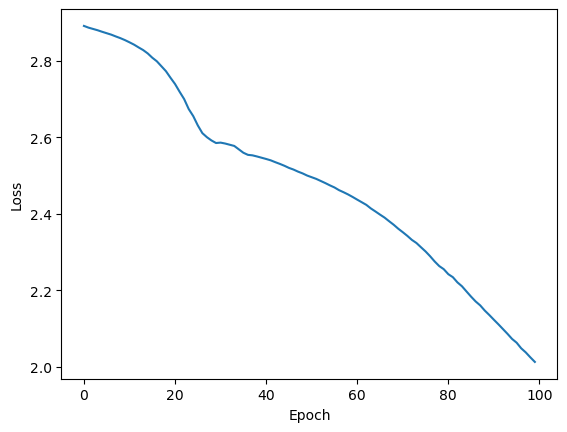

In [19]:
plt.plot(history.history['loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()


In [23]:
def gerar_texto(model, seed_text, next_chars, tokenizer, seq_length):
    for _ in range(next_chars):
            encoded = tokenizer.texts_to_sequences([seed_text])[0]
            encoded = np.array(encoded[-seq_length:]).reshape(1, seq_length)
            predicted = np.argmax(model.predict(encoded), axis=-1)
            out_char = tokenizer.sequences_to_texts([[predicted[0]]])[0]
            seed_text += " "+ out_char
    return seed_text

In [24]:
seed_text = 'Este'
generated = gerar_texto(model, seed_text, 30, tokenizer, seq_length)

print(generated)

ValueError: cannot reshape array of size 4 into shape (1,5)